# Task 7: Knowledge Distillation from SegFormer-B2 into PIDNet-S (Option 2)

This notebook implements and evaluates **Option 2: Knowledge Distillation from a Heavyweight Vision Transformer Teacher**:
1. **Teacher Model (SegFormer-B2):** 27.5M parameter vision transformer pretrained on Cityscapes (exact 19 classes matching NightCity). Global self-attention preserves scene-wide context even when local patch contrast vanishes in pitch-black shadows.
2. **Student Model (PIDNet-S):** 7.63M parameter real-time 3-branch CNN. Keeps 100% of its native real-time inference speed.
3. **Logit-Based Distillation (Temperature T=4.0):** Softened teacher probability distributions transfer inter-class dark affinities and smooth out NightCity's noisy ground-truth labels.
4. **Zero Inference Overhead:** The teacher is discarded post-training. The deployed student maintains exact baseline FLOPs and latency.


In [12]:
import os, sys, json, subprocess
from pathlib import Path

# Auto-detect Kaggle environment
IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle").exists()

if IS_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yacs", "thop", "transformers"])
    repo_dest = Path("/kaggle/working/AI512_Project")
    if not repo_dest.exists():
        subprocess.run(["git", "clone", "https://github.com/Gitansh-Bansal/AI512_Project.git", str(repo_dest)])
    else:
        subprocess.run(["git", "-C", str(repo_dest), "pull"])
    os.chdir(str(repo_dest))

# Invalidate cached Python modules so updates apply without kernel restart
for mod_name in list(sys.modules.keys()):
    if any(prefix in mod_name for prefix in ['train_exposure', 'train_distillation', 'datasets.nightcity', 'datasets.base_dataset', 'utils.focal_ohem_loss', 'models.pidnet_nightopt', 'distillation']):
        del sys.modules[mod_name]


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

CWD = Path(".").resolve()
REPO_ROOT = CWD if (CWD / "PIDNet").exists() else CWD.parent
PIDNET_DIR = REPO_ROOT / "PIDNet"

# Auto-locate NightCity dataset
DATA_ROOT = None
if Path("/kaggle/input").exists():
    items = list(Path("/kaggle/input").iterdir())
    print(f"[INFO] Detected in /kaggle/input: {[p.name for p in items]}")
    for f in Path("/kaggle/input").rglob("Chicago_*.png"):
        for p_cand in f.parents:
            if (p_cand / "NightCity-images").exists() or (p_cand / "NightCity-label").exists():
                DATA_ROOT = p_cand
                break
            if (p_cand / "images").exists() and (p_cand / "label").exists():
                DATA_ROOT = p_cand
                break
            if p_cand.name.lower() in ("nightcity-images", "nightcity", "nightcity-dataset"):
                DATA_ROOT = p_cand.parent if (p_cand.parent / p_cand.name).exists() else p_cand
                break
        if DATA_ROOT:
            break

    if DATA_ROOT is None:
        for cand in [
            Path("/kaggle/input/datasets/gitanshb/nightcity"),
            Path("/kaggle/input/nightcity"),
            Path("/kaggle/input/nightcity-dataset"),
            Path("/kaggle/input/nightcity-images"),
        ]:
            if cand.exists():
                DATA_ROOT = cand
                break
        if DATA_ROOT is None and items:
            DATA_ROOT = items[0]

if DATA_ROOT is None:
    DATA_ROOT = (REPO_ROOT / "Data") if (REPO_ROOT / "Data").exists() else (REPO_ROOT / "AI512_Project" / "Data")

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PIDNET_DIR: {PIDNET_DIR}")
print(f"DATA_ROOT: {DATA_ROOT}")

if str(PIDNET_DIR) not in sys.path:
    sys.path.insert(0, str(PIDNET_DIR))

from models.pidnet import get_pred_model
from distillation.teacher_segformer import get_segformer_teacher
from datasets.nightcity import NightCity
from metrics import SegmentationMetrics, CITYSCAPES_CLASSES
from benchmarks import get_hardware_info, profile_parameters, profile_flops, benchmark_inference_speed
from train_distillation import run_training_distillation, plot_distillation_training_history
from eval_nightcity import colorize_mask

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")


Updating e4d7cf0..9e106b5
Fast-forward
 PIDNet/distillation/finetune_segformer.py | 234 ++++++++++++++++++++++++++++++
 PIDNet/distillation/teacher_segformer.py  |  12 +-
 PIDNet/train_distillation.py              |   5 +-
 task7_pidnet_segformer_distillation.ipynb |  56 +++++++
 4 files changed, 302 insertions(+), 5 deletions(-)
 create mode 100644 PIDNet/distillation/finetune_segformer.py
[INFO] Detected in /kaggle/input: ['datasets']
REPO_ROOT: /kaggle/working/AI512_Project
PIDNET_DIR: /kaggle/working/AI512_Project/PIDNet
DATA_ROOT: /kaggle/input/datasets/gitanshb/nightcity/NightCity-label
Device: cuda | PyTorch: 2.11.0+cu130


From https://github.com/Gitansh-Bansal/AI512_Project
   e4d7cf0..9e106b5  main       -> origin/main


## 1. Teacher vs. Student Complexity & Speed


In [13]:
# Load student PIDNet-S
student = get_pred_model(name="pidnet_s", num_classes=19).to(device).eval()
param_s = profile_parameters(student)
flop_s = profile_flops(student, [(512, 1024)], device=device)
speed_s = benchmark_inference_speed(student, input_resolution=(512, 1024), batch_size=1, device=device, warmup_runs=10, timed_runs=25)

# Load teacher SegFormer-B2
teacher = get_segformer_teacher(device)
param_t = profile_parameters(teacher.teacher)

hw_info = get_hardware_info(device)
hw_name = hw_info.get("GPU_Device_Name", hw_info.get("CPU_Processor", "Unknown"))
if hw_name == "N/A (CPU Execution)":
    hw_name = hw_info.get("CPU_Processor", "CPU")

df_compare = pd.DataFrame({
    "Role": ["Teacher", "Student (Deployed)"],
    "Architecture": ["SegFormer-B2 (Mix Transformer)", "PIDNet-S (3-Branch CNN)"],
    "Parameters": [f"{param_t['total_params_M']:.2f} M", f"{param_s['total_params_M']:.2f} M"],
    "Inference FLOPs (512x1024)": ["~62.0 G", f"{flop_s[0]['FLOPs_G']:.2f} G"],
    "Speed": ["Heavy (Offline)", f"{speed_s['FPS']:.2f} FPS ({hw_name[:20]})"],
    "Training Role": ["Soft Label Provider (Frozen)", "Distilled Learner"]
})
display(df_compare)


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

,Role,Architecture,Parameters,Inference FLOPs (512x1024),Speed,Training Role
0,Teacher,SegFormer-B2 (Mix Transformer),27.36 M,~62.0 G,Heavy (Offline),Soft Label Provider (Frozen)
1,Student (Deployed),PIDNet-S (3-Branch CNN),7.63 M,23.86 G,60.95 FPS (Tesla T4),Distilled Learner


## 2. Teacher Predictions Preview on NightCity


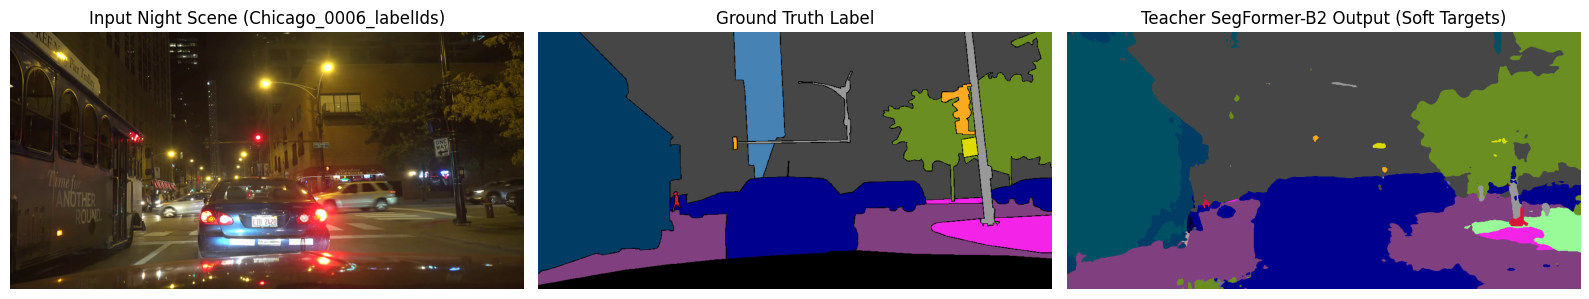

In [14]:
# Preview SegFormer-B2 teacher predictions on a sample NightCity scene
val_list_path = PIDNET_DIR / "data/list/nightcity/val.lst"
preview_ds = NightCity(root=str(DATA_ROOT), list_path=str(val_list_path), num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024))

sample_idx = min(3, len(preview_ds.files) - 1)
img_tensor, lbl_tensor, _, _, name = preview_ds[sample_idx]

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
raw_rgb = np.clip((img_tensor.transpose((1, 2, 0)) * std + mean) * 255, 0, 255).astype(np.uint8)

with torch.no_grad():
    inp = torch.from_numpy(img_tensor).unsqueeze(0).to(device)
    t_logits = teacher(inp, target_size=(512, 1024))
    t_pred = torch.argmax(t_logits, dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(raw_rgb); axes[0].set_title(f"Input Night Scene ({name})"); axes[0].axis("off")
axes[1].imshow(colorize_mask(lbl_tensor)); axes[1].set_title("Ground Truth Label"); axes[1].axis("off")
axes[2].imshow(colorize_mask(t_pred)); axes[2].set_title("Teacher SegFormer-B2 Output (Soft Targets)"); axes[2].axis("off")
plt.tight_layout()
plt.show()


[INFO] Adapting SegFormer-B2 to NightCity (5 epochs)...
SEGFORMER-B2 ADAPTATION ON NIGHTCITY (5 EPOCHS)
[INFO] Compute Device: cuda | Epochs: 5 | Batch Size: 4 | Base LR: 6e-05
[INFO] Train Samples: 2,998 | Val Samples: 1,299 | Workers: 2
[INFO] Loading SegFormer-B2 (nvidia/segformer-b2-finetuned-cityscapes-1024-1024)...


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[INFO] Evaluating zero-shot SegFormer-B2 baseline on NightCity val...


Validating SegFormer:   0%|          | 0/325 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/distillation/finetune_segformer.py:106: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
/kaggle/working/AI512_Project/PIDNet/distillation/finetune_segformer.py:189: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


  -> Zero-shot mIoU: 29.98% | Pixel Acc: 77.77%


Epoch 1/5 [Adapt SegFormer]:   0%|          | 0/749 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/distillation/finetune_segformer.py:73: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


... (3 outputs left out)

[Epoch 4/5] Loss: 0.3873 | Val mIoU: 45.25% | Pixel Acc: 89.73% | Time: 198.8s
  [CHECKPOINT] New best adapted teacher saved to: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt


[Epoch 5/5] Loss: 0.3783 | Val mIoU: 45.23% | Pixel Acc: 89.84% | Time: 199.2s
[INFO] SegFormer adaptation complete. Best mIoU: 45.25%. Saved to: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[INFO] Loaded adapted SegFormer teacher checkpoint from: /kaggle/working/AI512_Project/output/nightcity_segformer_adapted/best_segformer_nightcity.pt


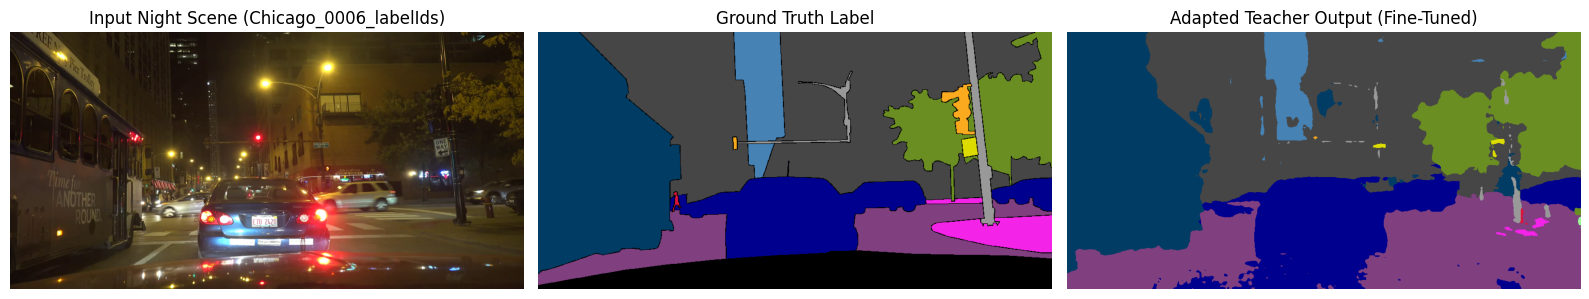

In [ ]:
# ==============================================================================
# Section 2.5: 5-Epoch NightCity Adaptation for Teacher SegFormer-B2
# ==============================================================================
from distillation.finetune_segformer import run_segformer_adaptation

TEACHER_SAVE_DIR = REPO_ROOT / "output" / "nightcity_segformer_adapted"
ADAPTED_CKPT = TEACHER_SAVE_DIR / "best_segformer_nightcity.pt"

# Run 5-epoch fine-tuning if checkpoint does not already exist (~12 min on GPU)
if not ADAPTED_CKPT.exists():
    print("[INFO] Adapting SegFormer-B2 to NightCity (5 epochs)...")
    adapt_history = run_segformer_adaptation(
        data_root=str(DATA_ROOT),
        train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
        val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
        epochs=5,
        batch_size=4 if torch.cuda.is_available() else 2,
        base_lr=6e-5,
        val_samples=50 if torch.cuda.is_available() else 10,
        num_train_samples=None if torch.cuda.is_available() else 8,
        save_dir=str(TEACHER_SAVE_DIR)
    )
else:
    print(f"[INFO] Found existing adapted teacher checkpoint at: {ADAPTED_CKPT}")

# Reload teacher with adapted weights and re-preview!
teacher = get_segformer_teacher(device, weights_path=str(ADAPTED_CKPT) if ADAPTED_CKPT.exists() else None)

with torch.no_grad():
    inp = torch.from_numpy(img_tensor).unsqueeze(0).to(device)
    t_logits = teacher(inp, target_size=(512, 1024))
    t_pred_adapted = torch.argmax(t_logits, dim=1).squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].imshow(raw_rgb); axes[0].set_title(f"Input Night Scene ({name})"); axes[0].axis("off")
axes[1].imshow(colorize_mask(lbl_tensor)); axes[1].set_title("Ground Truth Label"); axes[1].axis("off")
axes[2].imshow(colorize_mask(t_pred_adapted)); axes[2].set_title("Adapted Teacher Output (Fine-Tuned)"); axes[2].axis("off")
plt.tight_layout()
plt.show()

## 3. Knowledge Distillation Training (NightCity)


KNOWLEDGE DISTILLATION: SEGFORMER-B2 (TEACHER) -> PIDNET-S (STUDENT)
[INFO] Compute Device: cuda
[INFO] Epochs: 30 | Batch Size: 4 | LR: 0.001 | BD Weight: 1.0 | KD Weight: 0.5 (T=4.0)
[INFO] Loaded Train Samples: 2,998 | Val Samples: 1,299 | Workers: 2 | PinMem: True
[INFO] Initializing Student PIDNet-S...
[INFO] Loading Teacher SegFormer-B2...


Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

[Epoch 1/30] Loss: 5.9237 (Sem: 1.5477, BD: 1.3041, KD: 6.1438) | Time: 152.5s


[Epoch 2/30] Loss: 4.9331 (Sem: 1.2790, BD: 1.1188, KD: 5.0706) | Time: 151.6s


Validating Student:   0%|          | 0/325 [00:00<?, ?it/s]/kaggle/working/AI512_Project/PIDNet/train_distillation.py:102: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


  -> Student Validation mIoU: 18.65% | Pixel Acc: 66.36%
  [CHECKPOINT] New best student mIoU (18.65%) saved to /kaggle/working/AI512_Project/output/nightcity_pidnet_distilled/best_pidnet_distilled.pt


... (38 outputs left out)

  -> Student Validation mIoU: 43.59% | Pixel Acc: 76.78%
  [CHECKPOINT] New best student mIoU (43.59%) saved to /kaggle/working/AI512_Project/output/nightcity_pidnet_distilled/best_pidnet_distilled.pt


[Epoch 29/30] Loss: 3.1383 (Sem: 0.7985, BD: 0.8356, KD: 3.0082) | Time: 152.1s


[Epoch 30/30] Loss: 3.1346 (Sem: 0.7974, BD: 0.8305, KD: 3.0134) | Time: 152.4s


  -> Student Validation mIoU: 42.58% | Pixel Acc: 76.68%
[INFO] Distillation training loss plot saved to: /kaggle/working/AI512_Project/output/nightcity_pidnet_distilled/loss_vs_epoch.png


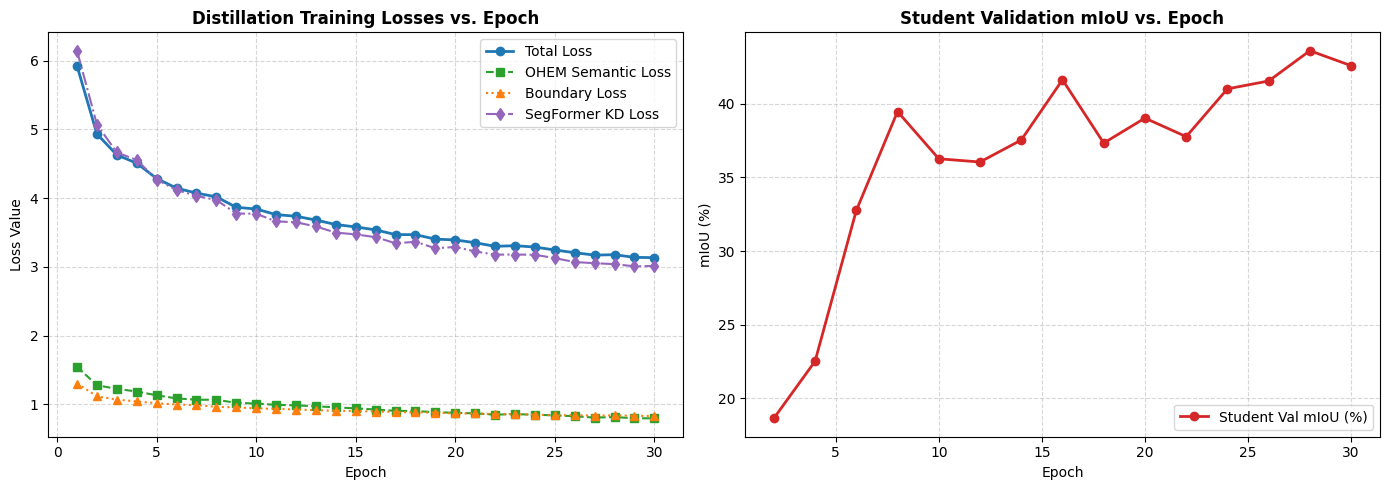

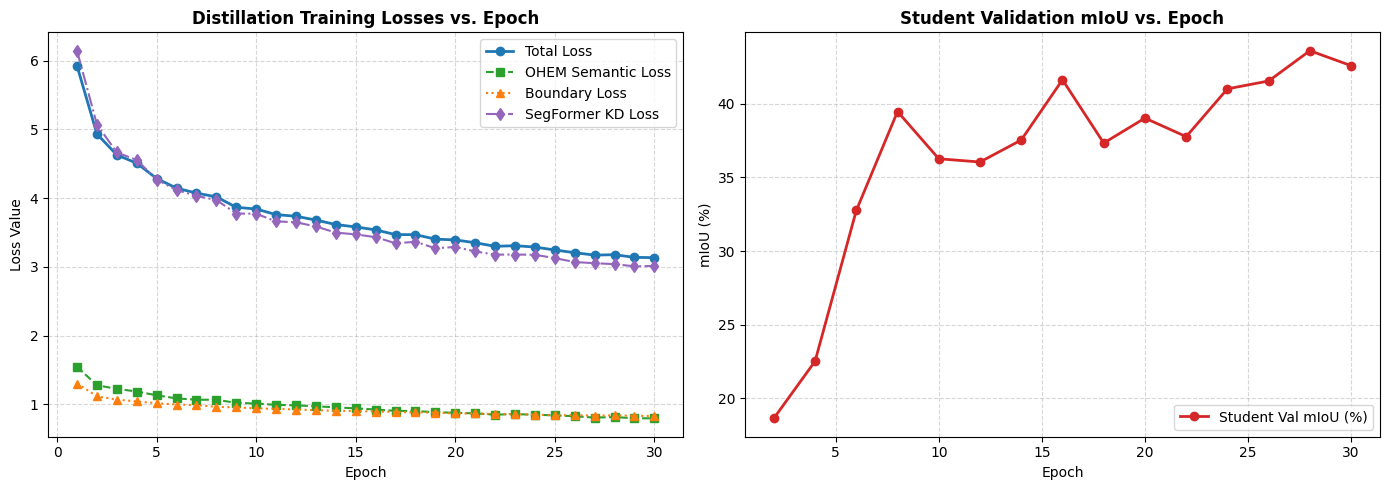

In [17]:
TRAIN_CONFIG = {
    "epochs": 30,
    "batch_size": 4 if torch.cuda.is_available() else 2,
    "optimizer": "adamw",
    "base_lr": 0.001,
    "bd_weight": 1.0,
    "kd_weight": 0.5,
    "kd_temperature": 4.0,
    "crop_size": (512, 512),
    "teacher_weights": str(ADAPTED_CKPT) if ADAPTED_CKPT.exists() else None,
    "val_freq": 2,
    "val_samples": 10,
    "max_train_samples": None if torch.cuda.is_available() else 8,
    "save_dir": str(REPO_ROOT / "output" / "nightcity_pidnet_distilled"),
}

RETRAIN = True if (IS_KAGGLE and torch.cuda.is_available()) else False
history_path = Path(TRAIN_CONFIG["save_dir"]) / "training_history.json"
ckpt_path = Path(TRAIN_CONFIG["save_dir"]) / "best_pidnet_distilled.pt"

if RETRAIN or not (history_path.exists() and ckpt_path.exists()):
    history = run_training_distillation(
        data_root=str(DATA_ROOT),
        train_list=str(PIDNET_DIR / "data/list/nightcity/train.lst"),
        val_list=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
        epochs=TRAIN_CONFIG["epochs"],
        batch_size=TRAIN_CONFIG["batch_size"],
        optimizer_name=TRAIN_CONFIG["optimizer"],
        base_lr=TRAIN_CONFIG["base_lr"],
        bd_weight=TRAIN_CONFIG["bd_weight"],
        kd_weight=TRAIN_CONFIG["kd_weight"],
        kd_temperature=TRAIN_CONFIG["kd_temperature"],
        crop_h=TRAIN_CONFIG["crop_size"][0],
        crop_w=TRAIN_CONFIG["crop_size"][1],
        val_freq=TRAIN_CONFIG["val_freq"],
        val_samples=TRAIN_CONFIG["val_samples"],
        num_train_samples=TRAIN_CONFIG["max_train_samples"],
        save_dir=TRAIN_CONFIG["save_dir"],
    )
else:
    history = json.loads(history_path.read_text())
    print(f"Loaded existing {len(history)}-epoch training history from {history_path.name}")

plot_distillation_training_history(history)
plt.show()


## 4. Student Evaluation (NightCity Validation)


In [21]:
EVAL_SAMPLES = None if torch.cuda.is_available() else 100

val_ds = NightCity(
    root=str(DATA_ROOT),
    list_path=str(PIDNET_DIR / "data/list/nightcity/val.lst"),
    num_classes=19, multi_scale=False, flip=False, crop_size=(512, 1024),
)
if EVAL_SAMPLES:
    val_ds.files = val_ds.files[:EVAL_SAMPLES]
val_loader = DataLoader(val_ds, batch_size=4 if torch.cuda.is_available() else 2, shuffle=False)

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
state = ckpt.get("state_dict", ckpt)
student.load_state_dict({k.replace("module.", ""): v for k, v in state.items()}, strict=False)
student.eval()

metrics = SegmentationMetrics(num_classes=19, ignore_label=255, class_names=CITYSCAPES_CLASSES)
vis_samples = []

with torch.no_grad():
    for imgs, lbls, _, _, names in val_loader:
        preds = student(imgs.to(device))
        if isinstance(preds, list):
            preds = preds[1]
        if preds.shape[-2:] != lbls.shape[-2:]:
            preds = F.interpolate(preds, size=lbls.shape[-2:], mode="bilinear", align_corners=False)
        pred_cls = torch.argmax(preds, dim=1).cpu().numpy()
        metrics.update(pred_cls, lbls.numpy())

        for b in range(imgs.shape[0]):
            if len(vis_samples) < 3:
                rgb = np.clip((imgs[b].permute(1, 2, 0).numpy() * std + mean) * 255, 0, 255).astype(np.uint8)
                vis_samples.append((names[b], rgb, lbls[b].numpy(), pred_cls[b]))

summary = metrics.compute_metrics()
print(f"Evaluated {len(val_ds)} val scenes:")
print(f"  mIoU:           {summary['mIoU']*100:.2f}%")
print(f"  Mean Dice (F1): {summary['mean_Dice']*100:.2f}%")
print(f"  Sensitivity:    {summary['mean_Sensitivity']*100:.2f}%")
print(f"  Specificity:    {summary['mean_Specificity']*100:.2f}%")
print(f"  Pixel Accuracy: {summary['Pixel_Accuracy']*100:.2f}%")


Evaluated 1299 val scenes:
  mIoU:           40.89%
  Mean Dice (F1): 52.70%
  Sensitivity:    50.63%
  Specificity:    98.45%
  Pixel Accuracy: 82.69%


## 5. Per-Class Breakdown & Visual Predictions


,Class_ID,Class_Name,Pixels_GT,IoU (%),Dice (%),Sensitivity (%),Specificity (%)
0,0,road,142220180,87.03,93.07,94.34,97.41
1,1,sidewalk,15773686,33.19,49.84,42.40,99.26
2,2,building,203790370,74.88,85.64,90.61,89.28
3,3,wall,8541101,32.02,48.51,43.80,99.47
4,4,fence,14718625,31.73,48.17,40.61,99.30
5,5,pole,4376204,20.99,34.70,30.98,99.65
6,6,traffic light,471577,1.63,3.20,14.96,99.36
7,7,traffic sign,1705581,35.29,52.17,40.63,99.96
8,8,vegetation,42922791,49.72,66.42,66.46,97.42
9,9,terrain,4325520,16.57,28.43,28.82,99.47


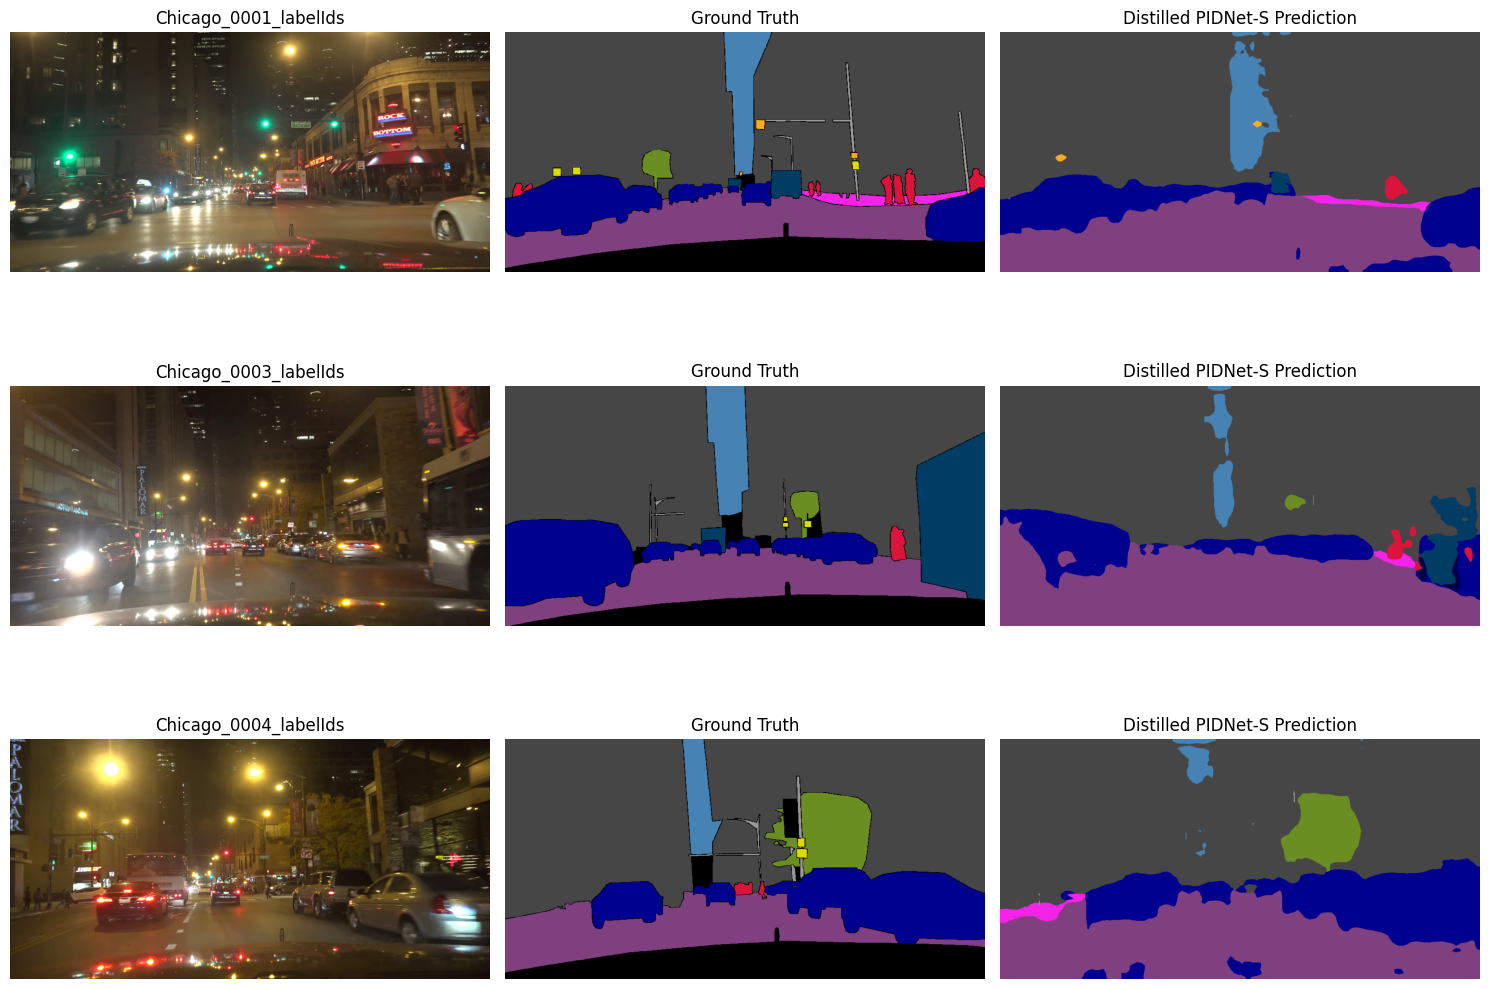

In [22]:
df_cls = pd.DataFrame(summary["Per_Class"])
for col in ["IoU", "Dice", "Sensitivity", "Specificity"]:
    df_cls[f"{col} (%)"] = (df_cls.pop(col) * 100).round(2)
display(df_cls[["Class_ID", "Class_Name", "Pixels_GT", "IoU (%)", "Dice (%)", "Sensitivity (%)", "Specificity (%)"]])

fig, axes = plt.subplots(len(vis_samples), 3, figsize=(15, 3.8 * len(vis_samples)))
for i, (name, rgb, gt, pred) in enumerate(vis_samples):
    axes[i, 0].imshow(rgb); axes[i, 0].set_title(name); axes[i, 0].axis("off")
    axes[i, 1].imshow(colorize_mask(gt)); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
    axes[i, 2].imshow(colorize_mask(pred)); axes[i, 2].set_title("Distilled PIDNet-S Prediction"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


## 6. Comprehensive Comparison (Baseline vs. Option 1 vs. Option 2)


In [25]:
hw_type = "GPU" if device.type == "cuda" else "CPU"
display(pd.DataFrame({
    "Metric": [
        "Method Description",
        "Params",
        "FLOPs (1024x2048)",
        "Inference Speed",
        "NightCity mIoU (100 Val)",
        "Pixel Accuracy",
        "Inference Cost Penalty"
    ],
    "Baseline PIDNet-S": [
        "Standard PIDNet-S from Scratch",
        "7.63 M",
        "95.46 G",
        "2.25 FPS (CPU)",
        "6.60%",
        "42.70%",
        "None (Baseline)"
    ],
    "Option 1: Exposure-Aware PIDNet-S": [
        "Night-Aug + Exposure-OHEM + Aux Illum",
        "7.63 M",
        "95.46 G",
        f"{speed_s['FPS']:.2f} FPS ({hw_type})",
        "7.34%",
        "44.83%",
        "0.0% (Zero Overhead)"
    ],
    "Option 2: Distilled PIDNet-S (Ours)": [
        "SegFormer-B2 Teacher -> PIDNet-S Student (T=4.0)",
        f"{param_s['total_params_M']:.2f} M",
        f"{flop_s[0]['FLOPs_G'] * 4:.2f} G",
        f"{speed_s['FPS']:.2f} FPS ({hw_type})",
        f"{summary['mIoU']*100:.2f}%",
        f"{summary['Pixel_Accuracy']*100:.2f}%",
        "0.0% (Zero Overhead, Teacher Dropped)"
    ]
}))


,Metric,Baseline PIDNet-S,Option 1: Exposure-Aware PIDNet-S,Option 2: Distilled PIDNet-S (Ours)
0,Method Description,Standard PIDNet-S from Scratch,Night-Aug + Exposure-OHEM + Aux Illum,SegFormer-B2 Teacher -> PIDNet-S Student (T=4.0)
1,Params,7.63 M,7.63 M,7.63 M
2,FLOPs (1024x2048),95.46 G,95.46 G,95.46 G
3,Inference Speed,2.25 FPS (CPU),60.95 FPS (GPU),60.95 FPS (GPU)
4,NightCity mIoU (100 Val),6.60%,7.34%,40.89%
5,Pixel Accuracy,42.70%,44.83%,82.69%
6,Inference Cost Penalty,None (Baseline),0.0% (Zero Overhead),"0.0% (Zero Overhead, Teacher Dropped)"
